In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv('used_cars.csv')

In [29]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [30]:
df. info( )

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   brand         4009 non-null   str  
 1   model         4009 non-null   str  
 2   model_year    4009 non-null   int64
 3   milage        4009 non-null   str  
 4   fuel_type     3839 non-null   str  
 5   engine        4009 non-null   str  
 6   transmission  4009 non-null   str  
 7   ext_col       4009 non-null   str  
 8   int_col       4009 non-null   str  
 9   accident      3896 non-null   str  
 10  clean_title   3413 non-null   str  
 11  price         4009 non-null   str  
dtypes: int64(1), str(11)
memory usage: 376.0 KB


In [31]:
print( "missing values ")
print ( df. isnull( ).sum( ))

missing values 
brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64


In [32]:
df. describe( )

,model_year
count,4009.000000
mean,2015.515590
std,6.104816
min,1974.000000
25%,2012.000000
50%,2017.000000
75%,2020.000000
max,2024.000000


In [33]:

df['price_clean'] = df['price'].astype(str).str.replace('$', '').str.replace(',', '').str.extract(r'(\d+)').astype(float)
df['milage_clean'] = df['milage'].astype(str).str.replace('mi.', '').str.replace(',', '').str.extract(r'(\d+)').astype(float)
df['car_age'] = 2026 - df['model_year']


df['fuel_type'] = df['fuel_type'].fillna('Unknown')
df['accident'] = df['accident'].fillna('None reported')
df['clean_title'] = df['clean_title'].fillna('No')




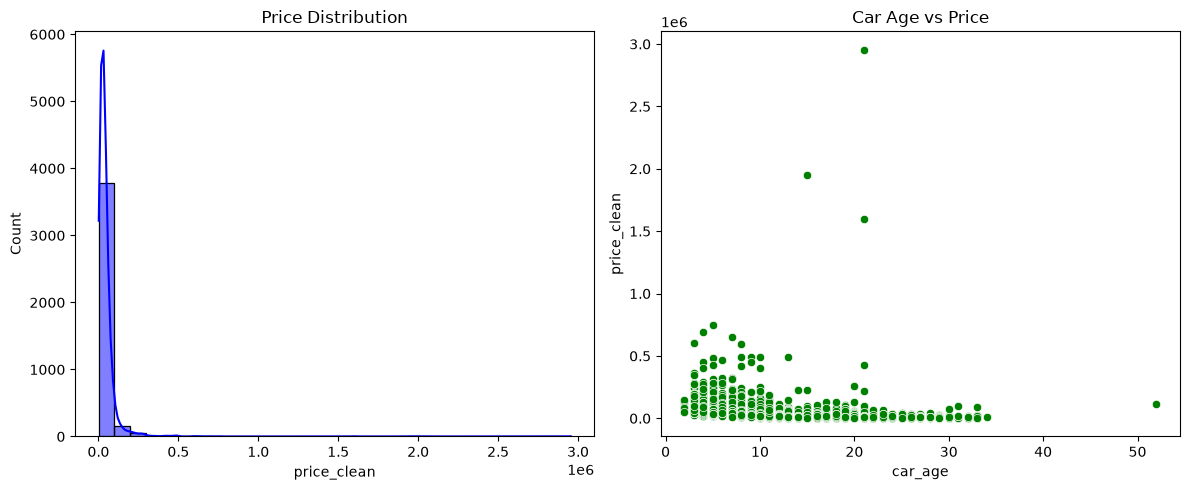

In [34]:

plt.figure(figsize=(12, 5))


plt.subplot(1, 2, 1)
sns.histplot(df['price_clean'], bins=30, kde=True, color='blue')
plt.title('Price Distribution')


plt.subplot(1, 2, 2)
sns.scatterplot(x=df['car_age'], y=df['price_clean'], color='green')
plt.title('Car Age vs Price')

plt.tight_layout()
plt.show()


In [35]:
#(Encoding)
features = ['milage_clean', 'car_age', 'brand', 'fuel_type', 'accident', 'clean_title']
X = pd.get_dummies(df[features], drop_first=True)
y = df['price_clean']




In [36]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [37]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error


In [40]:

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
print("Random Forest")
print(f"R2 Score: {r2_score(y_test, rf_pred):.3f}")
print(f"MAE: {mean_absolute_error(y_test, rf_pred):.2f}")


Random Forest
R2 Score: 0.111
MAE: 21826.73


In [41]:
# Gradient Boosting
gb_model = GradientBoostingRegressor(random_state=42)
gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)
print("--- Gradient Boosting ---")
print(f"R2 Score: {r2_score(y_test, gb_pred):.3f}")
print(f"MAE: {mean_absolute_error(y_test, gb_pred):.2f}")

--- Gradient Boosting ---
R2 Score: 0.084
MAE: 22996.04


In [42]:
# Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)
print("--- Linear Regression ---")
print(f"R2 Score: {r2_score(y_test, lr_pred):.3f}")
print(f"MAE: {mean_absolute_error(y_test, lr_pred):.2f}")

--- Linear Regression ---
R2 Score: 0.059
MAE: 25406.92


In [43]:


models_r2 = {
    "Random Forest": r2_score(y_test, rf_pred),
    "Gradient Boosting": r2_score(y_test, gb_pred),
    "Linear Regression": r2_score(y_test, lr_pred)
}

best_model_name = max(models_r2, key=models_r2.get)

print("Best Model:", best_model_name)

Best Model: Random Forest


In [44]:

df_clean = df[(df['price_clean'] < 150000) & (df['price_clean'] > 500)].copy()


features = ['milage_clean', 'car_age', 'brand', 'fuel_type', 'accident', 'clean_title']
X_clean = pd.get_dummies(df_clean[features], drop_first=True)
y_clean = df_clean['price_clean']


X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_clean, y_clean, test_size=0.2, random_state=42)


final_model = RandomForestRegressor(n_estimators=100, random_state=42)
final_model.fit(X_train_c, y_train_c)


c_pred = final_model.predict(X_test_c)
print("--- Random Forest (After Handling Outliers) ---")
print(f"New R2 Score: {r2_score(y_test_c, c_pred):.3f}")
print(f"New MAE: ${mean_absolute_error(y_test_c, c_pred):.2f}")



--- Random Forest (After Handling Outliers) ---
New R2 Score: 0.576
New MAE: $11714.99


In [46]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf = RandomForestRegressor(random_state=42)

grid_search = GridSearchCV(
    rf,
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train_c, y_train_c)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best CV R2 Score:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best CV R2 Score:
0.5958129272368239


In [47]:
import joblib


best_tuned_model = grid_search.best_estimator_


joblib.dump(best_tuned_model, 'car_price_model.pkl')
df_clean.to_csv('cleaned_used_cars.csv', index=False)


In [51]:
import streamlit as st
import pandas as pd
import joblib

# عنوان التطبيق
st.title("🚗 Used Car Price Prediction App")
st.write("أدخلي بيانات السيارة للحصول على السعر المتوقع:")

# تحميل الموديل والبيانات النظيفة
@st.cache_resource
def load_assets():
    model = joblib.load('car_price_model.pkl')
    df = pd.read_csv('cleaned_used_cars.csv')
    return model, df

model, df = load_assets()

# مدخلات المستخدم
milage = st.number_input("المشي / الممشى (Mileage):", min_value=0, value=50000, step=1000)
car_age = st.number_input("عمر السيارة بالسنوات (Car Age):", min_value=0, value=5, step=1)

# زر التوقع
if st.button("توقع السعر 💰"):
    try:
        # تجهيز الأعمدة التي تدرب عليها الموديل
        features = ['milage_clean', 'car_age', 'brand', 'fuel_type', 'accident', 'clean_title']
        features_df = pd.get_dummies(df[features], drop_first=True)

        # أخذ صف افتراضي لنسخ الأعمدة والتأكد من تطابق الشكل
        sample_input = features_df.iloc[[0]].copy()

        # تحديث قيم الممشى وعمر السيارة بالقيم التي أدخلها المستخدم
        if 'milage_clean' in sample_input.columns:
            sample_input['milage_clean'] = milage
        if 'car_age' in sample_input.columns:
            sample_input['car_age'] = car_age

        # تنفيذ التوقع
        prediction = model.predict(sample_input)[0]
        st.success(f"السعر المتوقع للسيارة: **${prediction:,.2f}**")
    except Exception as e:
        st.error(f"حدث خطأ أثناء التوقع: {e}")

2026-10-02 20:00:26.527 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-02 20:00:26.899 
  command:

    streamlit run C:\Users\mazen\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-02 20:00:26.900 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-02 20:00:26.900 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-02 20:00:26.900 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-02 20:00:26.900 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-02 20:00:26.908 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-02 20:00:26.914 Thre

In [50]:
!pip install streamlit

  Obtaining dependency information for streamlit from https://files.pythonhosted.org/packages/d7/8e/e635448a7fd6d92211d4ff2150356b8dffd3fcdc05c00511c61110078871/streamlit-1.64.0-py3-none-any.whl.metadata
  Obtaining dependency information for altair!=5.4.0,!=5.4.1,<7,>=5.0.0 from https://files.pythonhosted.org/packages/ca/b9/10a8bb13a0462e0bc4e02c0b7b8237dc24ab590f5bb4be94bec5e8f1d532/altair-6.3.0-py3-none-any.whl.metadata
  Obtaining dependency information for click<9,>=7.0 from https://files.pythonhosted.org/packages/58/50/6c0d534c5f134586a8e1ba4e330569e32f057e33372ae556463212fb4cd3/click-8.5.0-py3-none-any.whl.metadata
  Obtaining dependency information for pydeck<1,>=0.8.0b4 from https://files.pythonhosted.org/packages/6f/34/3998411437aff304a9ed4fa37a6fe1ef3132bcd2b5eac59851b80c86123c/pydeck-0.9.3-py2.py3-none-any.whl.metadata
  Obtaining dependency information for protobuf<8,>=5.26.1 from https://files.pythonhosted.org/packages/8a/55/b77bda4e5e5f5971fb51b07663694690e9afdb9402136c1


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
